### Лабораторна робота №3. Дерева прийняття рішень

In [1]:
import pandas as pd

In [2]:
# 1. Відкрити та зчитати файл з даними.
file_path = "Input_Lab-2_3_4_WQ-R.csv"
data = pd.read_csv(file_path, delimiter=";")

In [3]:
# 2. Визначити та вивести кількість записів, а також кількість полів та їх тип у завантаженому наборі даних.
num_records = len(data)
num_fields = len(data.columns)
field_types = data.dtypes

print(f"Кількість записів: {num_records}")
print(f"Кількість полів: {num_fields}")
print("Типи полів:")
print(field_types)

Кількість записів: 1599
Кількість полів: 12
Типи полів:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [4]:
# 3. Вивести перші 10 записів набору даних.
print("\nТипи полів кожного запису:")
print(data.head(10))


Типи полів кожного запису:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   
5            7.4              0.66         0.00             1.8      0.075   
6            7.9              0.60         0.06             1.6      0.069   
7            7.3              0.65         0.00             1.2      0.065   
8            7.8              0.58         0.02             2.0      0.073   
9            7.5              0.50         0.36             6.1      0.071   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                 

In [5]:
# 4. Розділити набір даних на навчальну (тренувальну) та тестову вибірки.
from sklearn.model_selection import ShuffleSplit

# Визначення вхідних ознак (X) та цільової змінної (y) тренувальних та тестових вибірок
def get_train_and_test_sets(data):
    # the dataset is broken into two parts in a ratio of 75:25
    shuffle_split = ShuffleSplit(n_splits=1, test_size=0.25, random_state=16)
    train_index, test_index = next(shuffle_split.split(data))

    train_data = data.iloc[train_index]
    test_data = data.iloc[test_index]
    
    X_train = train_data.drop('quality', axis=1)
    y_train = train_data['quality']

    X_test = test_data.drop('quality', axis=1)
    y_test = test_data['quality']

    return X_train, y_train, X_test, y_test

In [6]:
# 5. Використовуючи відповідні функції бібліотеки scikit-learn, збудувати класифікаційну модель логістичної регресії та навчити її на тренувальній вибірці, 
# вважаючи, що цільова характеристика визначається стовпчиком HighQuality, а всі інші виступають в ролі вихідних аргументів.

from sklearn.tree import DecisionTreeClassifier

def generate_decision_tree_model(X_train, y_train, max_depth=5, min_samples_leaf=1):
    # Побудова моделі дерева прийняття рішень
    clf = DecisionTreeClassifier(max_depth=max_depth)

    # Навчання моделі на тренувальній вибірці
    return clf.fit(X_train, y_train)

X_train, y_train, X_test, y_test = get_train_and_test_sets(data)
decision_tree_model = generate_decision_tree_model(X_train, y_train, max_depth=5)

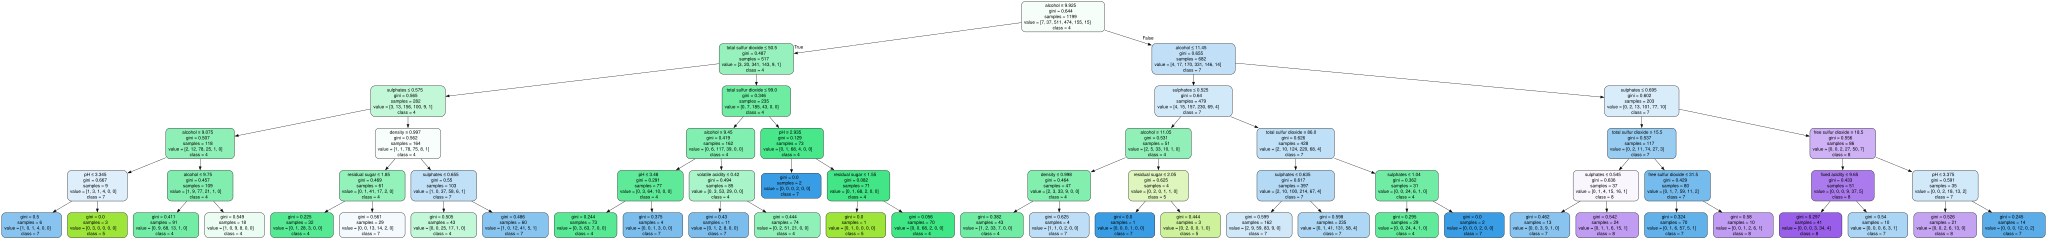

In [7]:
# 6. Представити графічно побудоване дерево за допомогою бібліотеки graphviz.

# %conda install graphviz
# %conda install python-graphviz
# %pip install graphviz

from sklearn import tree
import graphviz

graphviz.__version__, graphviz.version()

# Експортуємо дерево у файл .dot
dot_data = tree.export_graphviz(decision_tree_model, out_file=None,
                                feature_names=X_train.columns, class_names=y_train.astype(str).unique(), 
                                filled=True, rounded=True, special_characters=True)
# Побудова графу з файла .dot
graph = graphviz.Source(dot_data)
# Відображення графу
graph.render("decision_tree.dot")
graph

Кількість записів з класом quality - 3: 10
Кількість записів з класом quality - 4: 53
Кількість записів з класом quality - 8: 18
Класифікаційний звіт для тренувальної вибірки:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         7
           4       0.86      0.16      0.27        37
           5       0.78      0.72      0.75       511
           6       0.60      0.79      0.68       474
           7       0.71      0.44      0.54       155
           8       0.00      0.00      0.00        15

    accuracy                           0.68      1199
   macro avg       0.49      0.35      0.37      1199
weighted avg       0.69      0.68      0.67      1199

Класифікаційний звіт для тестової вибірки:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         3
           4       0.33      0.06      0.11        16
           5       0.73      0.58      0.65       170
           6       0.

/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classif

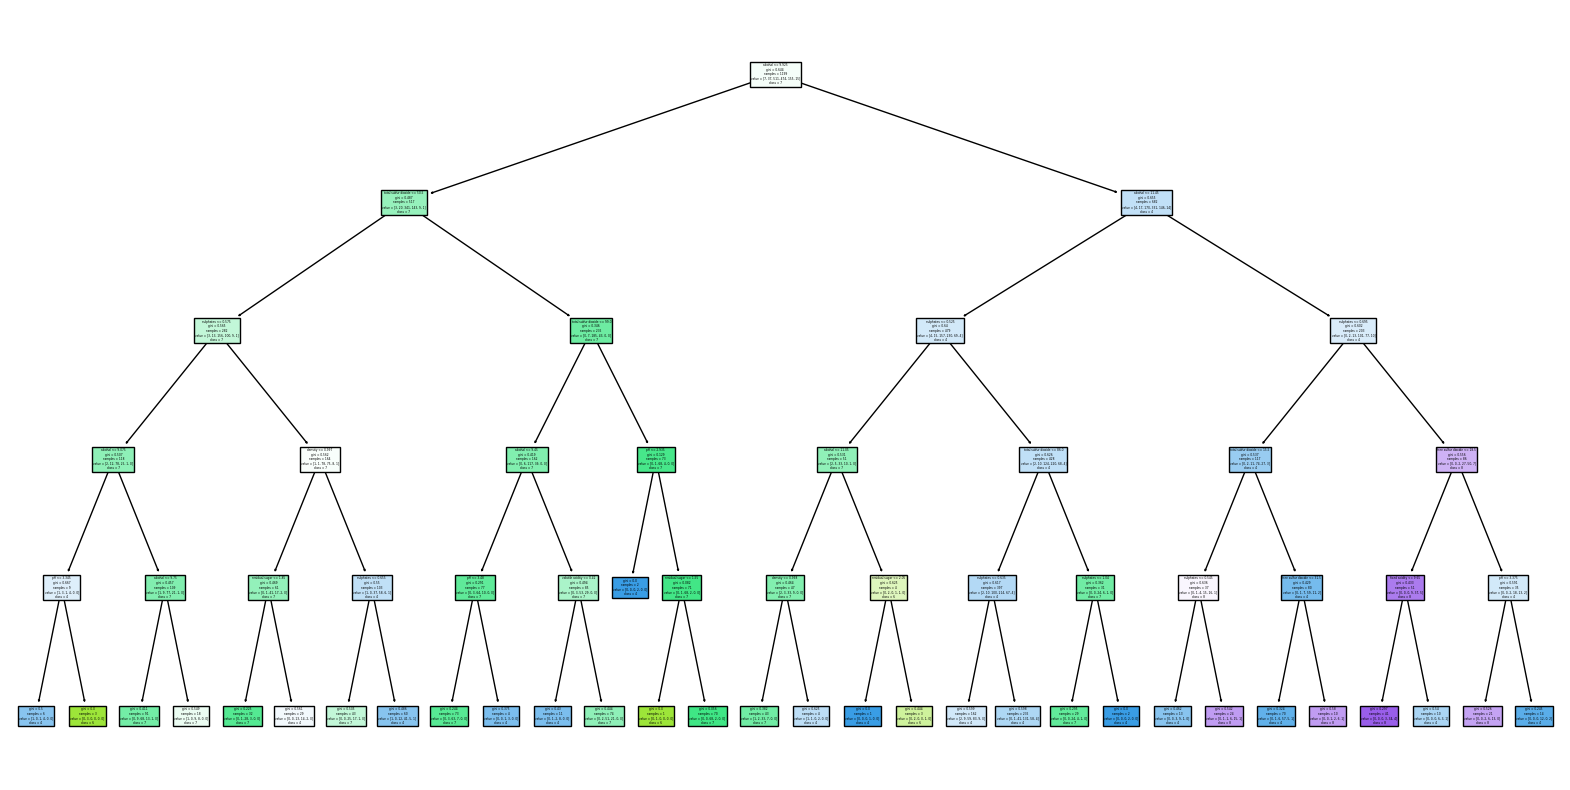

Точність моделі з критерієм ентропії: 0.565
Точність моделі з критерієм Джині: 0.61


In [8]:
# 7. Обчислити класифікаційні метрики збудованої моделі для тренувальної та тестової вибірки. Представити результати роботи моделі на тестовій
# вибірці графічно. Порівняти результати, отриманні при застосуванні різних критеріїв розщеплення: інформаційний приріст на основі ентропії чи неоднорідності Джині.

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import numpy as np

print(f"Кількість записів з класом quality - 3: {data['quality'].value_counts()[3]}")
print(f"Кількість записів з класом quality - 4: {data['quality'].value_counts()[4]}")
print(f"Кількість записів з класом quality - 8: {data['quality'].value_counts()[8]}")

# Обчислення класифікаційних метрик для тренувальної вибірки
train_pred = decision_tree_model.predict(X_train)
print("Класифікаційний звіт для тренувальної вибірки:")
print(classification_report(y_train, train_pred))

# Обчислення класифікаційних метрик для тестової вибірки
test_pred = decision_tree_model.predict(X_test)
print("Класифікаційний звіт для тестової вибірки:")
print(classification_report(y_test, test_pred))

# Графічне представлення результатів на тестовій вибірці
plt.figure(figsize=(20,10))
plot_tree(decision_tree_model, filled=True, feature_names=data.columns[:-1], class_names=data['quality'].astype(str).unique())
plt.show()

# Порівняння результатів з різними критеріями розщеплення, які налаштовуються при побудові моделі.
clf_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=5)
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=5)

clf_entropy.fit(X_train, y_train)
clf_gini.fit(X_train, y_train)

# Оцінка точності моделей
accuracy_entropy = accuracy_score(y_test, clf_entropy.predict(X_test))
accuracy_gini = accuracy_score(y_test, clf_gini.predict(X_test))

print("Точність моделі з критерієм ентропії:", accuracy_entropy)
print("Точність моделі з критерієм Джині:", accuracy_gini)

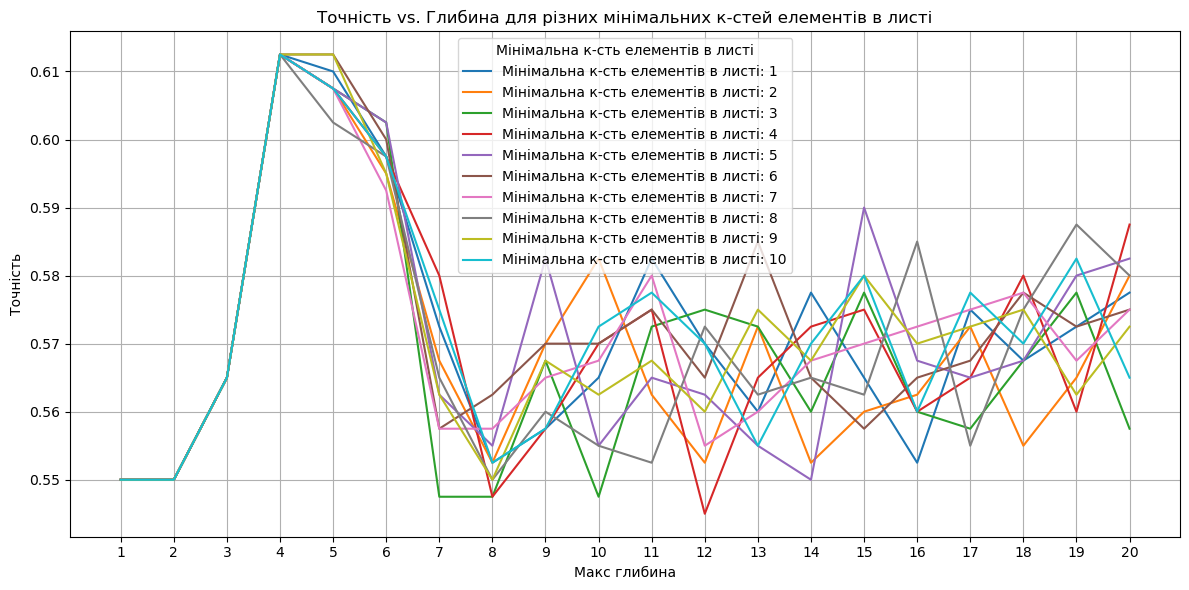

In [9]:
# 8. З’ясувати вплив глибини дерева та мінімальної кількості елементів в листі дерева на результати класифікації. Результати представити графічно.

# List to store accuracy scores
depths = range(1, 21)
min_samples_leaf_values = range(1, 11)
accuracy_scores = np.zeros((len(depths), len(min_samples_leaf_values)))

# Iterating over different values of depth and min_samples_leaf
for i, depth in enumerate(depths):
    for j, min_samples_leaf in enumerate(min_samples_leaf_values):
        # Building and training Decision Tree model
        clf = generate_decision_tree_model(X_train, y_train, max_depth=depth, min_samples_leaf=min_samples_leaf)
        
        # Predicting on testing set and computing accuracy
        y_pred = clf.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        
        # Storing accuracy
        accuracy_scores[i, j] = accuracy

# Plotting
plt.figure(figsize=(12, 6))
for j, min_samples_leaf in enumerate(min_samples_leaf_values):
    plt.plot(depths, accuracy_scores[:, j], label=f'Мінімальна к-сть елементів в листі: {min_samples_leaf}')

plt.title('Точність vs. Глибина для різних мінімальних к-стей елементів в листі')
plt.xlabel('Макс глибина')
plt.ylabel('Точність')
plt.xticks(depths)
plt.legend(title='Мінімальна к-сть елементів в листі')
plt.grid(True)
plt.tight_layout()
plt.show()

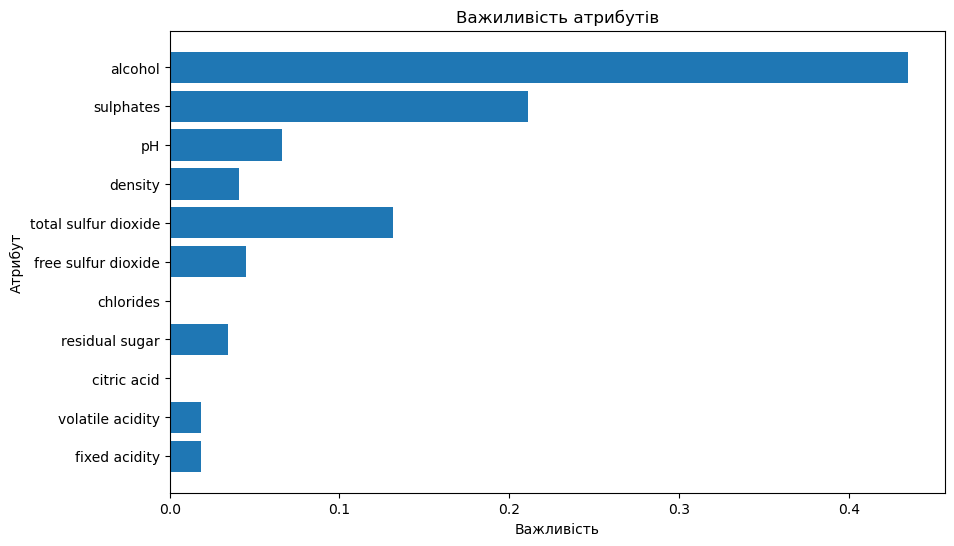

In [10]:
# 9. Навести стовпчикову діаграму важливості атрибутів, які використовувалися для класифікації (див. feature_importances_).
# Пояснити, яким чином – на Вашу думку – цю важливість можна підрахувати.

# Getting feature importances
importances = decision_tree_model.feature_importances_

# Getting feature names
feature_names = data.columns[:-1]

# Plotting feature importances
plt.figure(figsize=(10, 6))
plt.barh(range(len(importances)), importances, tick_label=feature_names)
plt.xlabel('Важливість')
plt.ylabel('Атрибут')
plt.title('Важиливість атрибутів')
plt.show()

In [11]:
def gini_impurity(labels):
    """Calculate Gini impurity for a list of labels."""
    total_samples = len(labels)
    if total_samples == 0:
        return 0

    # Count the occurrences of each label
    label_counts = {}
    for label in labels:
        if label in label_counts:
            label_counts[label] += 1
        else:
            label_counts[label] = 1

    # Calculate Gini impurity
    impurity = 1
    p_label_sum = 0
    for label in label_counts:
        p_label = label_counts[label] / total_samples
        p_label_sum += p_label ** 2

    return impurity - p_label_sum

# Example usage:
print("Gini impurity:", gini_impurity(data['quality']))

Gini impurity: 0.6426632342524897
